In [1]:
import os
import glob as gb
import json
import re
import numpy as np
import pandas as pd
import cv2
from collections import deque
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import torch
import sys
sys.path.append("..")

import utils

import warnings
warnings.filterwarnings("ignore")
import argparse

In [1]:
import torch
import torch.nn as nn
import math

class SphericalAngularLoss(nn.Module):
    """
    PyTorch module to compute angular distance between predicted and true angles
    in spherical coordinates (azimuth and elevation).
    - Azimuth: horizontal angle in range [-180, 180]
    - Elevation: vertical angle in range [-90, 90]
    """
    def __init__(self, reduction='mean'):
        super().__init__()
        self.reduction = reduction
    
    def compute_azimuth_diff(self, pred, true):
        # Convert degrees to radians
        pred_rad = pred * math.pi / 180.0
        true_rad = true * math.pi / 180.0
        
        # Calculate the absolute angular difference
        diff = torch.abs(true_rad - pred_rad)
        
        # Handle wraparound for azimuth: ensure we get the smaller angle
        diff = torch.min(diff, 2 * math.pi - diff)
        
        # Convert back to degrees
        return diff * 180.0 / math.pi
    
    def compute_elevation_diff(self, pred, true):
        # For elevation, we just need the absolute difference
        # No wraparound needed since it's bounded at ±90°
        return torch.abs(pred - true)
    
    def forward(self, y_pred, y_true):
        """
        Args:
            y_pred: tensor of shape [..., 2] where [..., 0] is azimuth and [..., 1] is elevation
            y_true: tensor of shape [..., 2] where [..., 0] is azimuth and [..., 1] is elevation
        """
        # Split predictions and true values into azimuth and elevation
        pred_azimuth, pred_elevation = y_pred[..., 0], y_pred[..., 1]
        true_azimuth, true_elevation = y_true[..., 0], y_true[..., 1]
        
        # Compute differences
        azimuth_diff = self.compute_azimuth_diff(pred_azimuth, true_azimuth)
        elevation_diff = self.compute_elevation_diff(pred_elevation, true_elevation)
        
        # Combine differences
        combined_diff = torch.stack([azimuth_diff, elevation_diff], dim=-1)
        
        if self.reduction == 'mean':
            return torch.mean(combined_diff)
        elif self.reduction == 'sum':
            return torch.sum(combined_diff)
        else:  # 'none'
            return combined_diff

class SphericalMSELoss(nn.Module):
    """
    Mean Squared Error loss that accounts for spherical coordinates.
    """
    def __init__(self, reduction='mean'):
        super().__init__()
        self.angular_loss = SphericalAngularLoss(reduction='none')
        self.reduction = reduction
    
    def forward(self, y_pred, y_true):
        angular_diff = self.angular_loss(y_pred, y_true)
        squared_diff = torch.square(angular_diff)
        
        if self.reduction == 'mean':
            return torch.mean(squared_diff)
        elif self.reduction == 'sum':
            return torch.sum(squared_diff)
        else:  # 'none'
            return squared_diff
        
# Initialize loss function
criterion = SphericalMSELoss()

# Example predictions and ground truth
# Shape: [batch_size, 2] (azimuth, elevation)
predictions = torch.tensor([
    [170.0, 80.0],   # [azimuth, elevation]
    [-170.0, -85.0]
])

ground_truth = torch.tensor([
    [175.0, 85.0],
    [-175.0, -80.0]
])

# Compute loss
loss = criterion(predictions, ground_truth)
loss

tensor(25.0001)

In [4]:
import torch
import math

def compute_spherical_motion(angles, time_delta=1/30.0):
    """
    Compute differences and velocities for both horizontal and vertical angles.
    
    Args:
        angles: tensor of shape (T, 2) where:
               [:, 0] is horizontal angle in range [-180, 180]
               [:, 1] is vertical angle in range [-90, 90]
        time_delta: float, time between consecutive samples in seconds
    
    Returns:
        Dictionary containing:
        - differences: angle differences (wrapped appropriately) shape (T, 2)
        - velocities: angular velocities in degrees per second shape (T, 2)
    """
    # Extract horizontal and vertical angles
    horz = angles[:, 0]  # Shape: (T,)
    vert = angles[:, 1]  # Shape: (T,)
    
    # Compute differences
    horz_diff = horz[1:] - horz[:-1]  # Shape: (T-1,)
    vert_diff = vert[1:] - vert[:-1]  # Shape: (T-1,)
    
    # Handle wrapping for horizontal angles
    horz_diff = torch.where(horz_diff > 180, horz_diff - 360, horz_diff)
    horz_diff = torch.where(horz_diff < -180, horz_diff + 360, horz_diff)
    
    # Pad to maintain original length
    horz_diff = torch.cat([horz_diff[:1], horz_diff])  # Shape: (T,)
    vert_diff = torch.cat([vert_diff[:1], vert_diff])  # Shape: (T,)
    
    # Stack differences back to original shape
    differences = torch.stack([horz_diff, vert_diff], dim=1)  # Shape: (T, 2)
    
    # Compute velocities (degrees per second)
    velocities = differences / time_delta
    
    return {
        'differences': differences,  # Shape: (T, 2)
        'velocities': velocities,    # Shape: (T, 2)
        'horz_diff': horz_diff,      # Shape: (T,)
        'vert_diff': vert_diff,      # Shape: (T,)
        'horz_vel': horz_diff / time_delta,  # Shape: (T,)
        'vert_vel': vert_diff / time_delta   # Shape: (T,)
    }

# Example usage
def example_usage():
    # Create sample data: (15, 2)
    sequence = torch.tensor([
        [170, 80],   # [horz, vert]
        [175, 85],
        [-175, 87],
        [-170, 85],
        [-165, 80],
        # ... more timesteps
    ]).float()
    
    # Compute motion
    motion = compute_spherical_motion(sequence)
    
    print("Input shape:", sequence.shape)
    print("Differences shape:", motion['differences'].shape)
    print("Velocities shape:", motion['velocities'].shape)
    
    # Print sample values
    print("\nHorizontal differences:", motion['horz_diff'])
    print("Vertical differences:", motion['vert_diff'])
    print("Horizontal velocities:", motion['horz_vel'])
    print("Vertical velocities:", motion['vert_vel'])
    
    return motion
example_usage()

Input shape: torch.Size([5, 2])
Differences shape: torch.Size([5, 2])
Velocities shape: torch.Size([5, 2])

Horizontal differences: tensor([ 5.,  5., 10.,  5.,  5.])
Vertical differences: tensor([ 5.,  5.,  2., -2., -5.])
Horizontal velocities: tensor([150.0000, 150.0000, 300.0000, 150.0000, 150.0000])
Vertical velocities: tensor([ 150.0000,  150.0000,   60.0000,  -60.0000, -150.0000])


{'differences': tensor([[ 5.,  5.],
         [ 5.,  5.],
         [10.,  2.],
         [ 5., -2.],
         [ 5., -5.]]),
 'velocities': tensor([[ 150.0000,  150.0000],
         [ 150.0000,  150.0000],
         [ 300.0000,   60.0000],
         [ 150.0000,  -60.0000],
         [ 150.0000, -150.0000]]),
 'horz_diff': tensor([ 5.,  5., 10.,  5.,  5.]),
 'vert_diff': tensor([ 5.,  5.,  2., -2., -5.]),
 'horz_vel': tensor([150.0000, 150.0000, 300.0000, 150.0000, 150.0000]),
 'vert_vel': tensor([ 150.0000,  150.0000,   60.0000,  -60.0000, -150.0000])}

In [7]:
def parse_arguments():
    parser = argparse.ArgumentParser(description="Script for processing video dataset and applying models.")
    
    parser.add_argument(
        '--cut_dataset_path', 
        type=str, 
        default='/mnt/DataLake/AlienBackup/access/processed_dataset/eht_dataset_prossesed_vid',
        help="Path to the processed dataset directory."
    )
    parser.add_argument(
        '--raw_videos_path', 
        type=str, 
        default='/mnt/DataLake/AlienBackup/access/eht_dataset/Videos/*.mp4',
        help="Path to the raw videos."
    )
    parser.add_argument(
        '--save_video', 
        type=bool, 
        default=False,
        help="Flag to save the video with the prediction of 6th timestep in the future (True/False)."
    )
    parser.add_argument(
        '--trained_model_folder', 
        type=str, 
        default='trained_models_combined',
        help="Path to the folder containing the trained models."
    )
    parser.add_argument(
        '--model_base_name', 
        type=str, 
        default='conv_tsmixer_past_15_future_6_window_15_20241203_181554',
        help="Base name for the model being used."
    )
    parser.add_argument(
        '--model_epoch_name_path', 
        type=str, 
        default='model_epoch_8_val_loss_0.0053.pth',
        help="Path to the specific model epoch file."
    )
    parser.add_argument(
        '--sal_path', 
        type=str, 
        default='/mnt/DataLake/AlienBackup/access/eht_gaze_prediction/models/unisal.pth',
        help="Path to the SAL model file."
    )
    
    parser.add_argument(
        '--folder_save_path', 
        type=str, 
        default='/mnt/DataLake/AlienBackup/access/results_combined_models',
        help="Path to the folder where outputs will be saved."
    )
    
    
    return parser.parse_args()

args = parse_arguments()

In [8]:
args

Namespace(cut_dataset_path='/mnt/DataLake/AlienBackup/access/processed_dataset/eht_dataset_prossesed_vid', raw_videos_path='/mnt/DataLake/AlienBackup/access/eht_dataset/Videos/*.mp4', save_video=False, trained_model_folder='trained_models_combined', model_base_name='conv_tsmixer_past_15_future_6_window_15_20241203_181554', model_epoch_name_path='model_epoch_8_val_loss_0.0053.pth', sal_path='/mnt/DataLake/AlienBackup/access/eht_gaze_prediction/models/unisal.pth', folder_save_path='/home/christos/.local/share/jupyter/runtime/kernel-v384cf17ff7278180872eb26b6bf86a7f08665dbe4.json')

100%|██████████| 80/80 [00:17<00:00,  4.68it/s]

['/mnt/DataLake/AlienBackup/access/eht_dataset/Videos/Video 8 - LOSC Football.mp4']
MSE x, y: [160.96789087 186.64830451 221.4743356  262.93268869 315.19818716
 382.97631891] [33.06376245 32.95799097 33.85052096 33.74600919 34.07310467 36.46336223]
RMSE x, y: [12.6873122  13.66192902 14.88201383 16.21519931 17.75382176 19.56978076] [5.75010978 5.74090507 5.81812005 5.80913153 5.8372172  6.03849006]


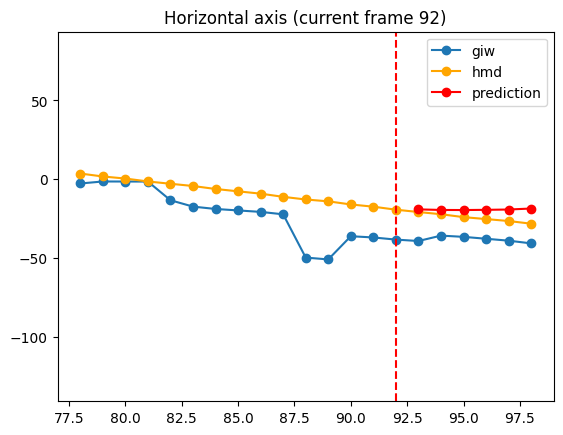

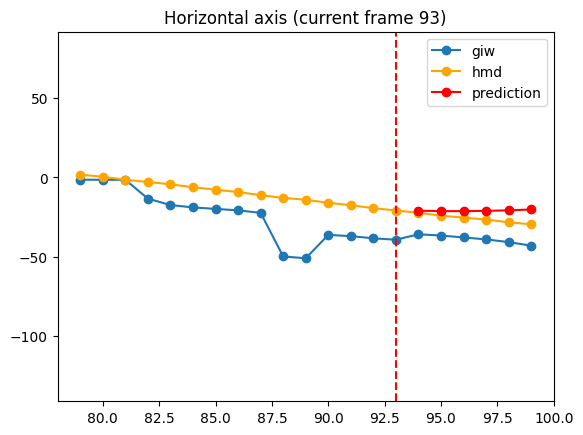

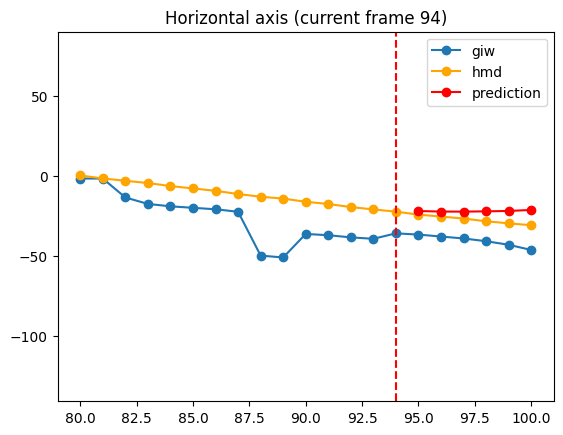

In [31]:

test_parent_folder = (
        os.path.join(args.cut_dataset_path,"Video_8","User_8_Task_1"),
        # os.path.join(args.cut_dataset_path,"Video_1","User_9_Task_1")
    )

json_paths_videos = []
for test_path in test_parent_folder:
    json_paths = gb.glob(os.path.join(test_path, "*.json"))
    json_paths.sort(key=utils.natural_keys)
    json_paths_videos.append(json_paths)

raw_video_paths = gb.glob(args.raw_videos_path)

raw_video_path = []
metadata_videos = []
for json_paths in tqdm(json_paths_videos):
    metadata = []
    for json_path in json_paths:
        with open(json_path, "r") as f:
            data = json.load(f)
            df = pd.DataFrame(data)
            metadata.append(df)
    
    metadata = pd.concat(metadata, ignore_index=True)
    video_id = metadata.iloc[0]['video_id']
    raw_video_path.extend([path for path in raw_video_paths if f"Video {video_id} " in path])
    metadata_videos.append(metadata)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

unisal_model = utils.load_unisal(args.sal_path, device)

time_model, timepoints, future_steps = utils.load_time_model(args.trained_model_folder, args.model_base_name, args.model_epoch_name_path, device)

# Create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec

# Initliaze raw video capture
for idx_video, raw_video in enumerate(raw_video_path):
    preds = []
    preds_giw_diff = []
    ground_truth = []
    gt_giw_diff = []
    all_previous_giw = []
    all_previous_hmd = []
    cap = cv2.VideoCapture(raw_video)
    if not cap.isOpened():
        print(f"Error: Could not open video {raw_video}.")
        continue
    
    metadata = metadata_videos[idx_video]
    # os.makedirs(f"{args.folder_save_path}/{args.model_base_name}", exist_ok=True)
    if args.save_video:
        output_video = cv2.VideoWriter(
        f"{args.folder_save_path}/{args.model_base_name}/pred6_{metadata.iloc[0]['video_id']}_{metadata.iloc[0]['user_id']}_{metadata.iloc[0]['task_id']}.mp4",
        fourcc,
        30.0,
        (1280, 720),
        )
    
    sal_frames = []
    # Create salency maps for timepoints-1 frames and save to sal_frames list
    for i in tqdm(range(timepoints-1)):
        fnumber = metadata.iloc[i]["frame_number"]
        cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber)
        frame = cap.read()[1]
        if frame is None:
            continue
        frame_tensor = torch.tensor(np.array([utils.preprocess_sal_img(frame)]), dtype=torch.float32)
        with torch.no_grad():
            sal_frame = unisal_model(frame_tensor.unsqueeze(0).to(device))
        sal_frames.append(sal_frame.squeeze().squeeze())

    for i in tqdm(range(timepoints-1, 100 - future_steps)): # len(metadata) for the whole video
        # Get the last {current} frame
        fnumber = metadata.iloc[i]["frame_number"]
        cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber)
        original_frame = cap.read()[1]
        if original_frame is None:
            continue
        frame = utils.preprocess_sal_img(original_frame)
        
        frame_tensor = torch.tensor(np.array([frame]), dtype=torch.float32)
        # Load timepoint metadata
        meta_timepoints = metadata.iloc[i-timepoints+1: i+1]
        current_frame_data = meta_timepoints.iloc[-1]

        hmd_ang_vel_long = utils.calculate_angular_velocity(
            meta_timepoints["horz_hmd_deg"].to_numpy()
        )
        hmd_ang_vel_lat = utils.calculate_angular_velocity(
            meta_timepoints["vert_hmd_deg"].to_numpy()
        )
        hmd_ang_diff_long = utils.calculate_angle_diff(meta_timepoints["horz_hmd_deg"].to_numpy())
        hmd_ang_diff_lat = utils.calculate_angle_diff(meta_timepoints["vert_hmd_deg"].to_numpy())
        # Load current gaze and future gaze
        future_metadata_timepoints = metadata.iloc[i+1 : i+1+future_steps]
        giw_angdiff_long = (
            future_metadata_timepoints["giw_long"]
            - current_frame_data["horz_hmd_deg"]
        ) / 360
        giw_angdiff_lat = (
            future_metadata_timepoints["giw_lat"]
            - current_frame_data["vert_hmd_deg"]
        ) / 180

        # Load saliency maps
        with torch.no_grad():
            sal_frame = unisal_model(frame_tensor.unsqueeze(0).to(device))

        sal_frames.append(sal_frame.squeeze().squeeze())
        if len(sal_frames)>timepoints:
            sal_frames.pop(0)
        # Normalize frames to the range [-1, 1]
        sal_frames_processed = utils.sal_process(torch.stack(sal_frames, dim=0).cpu().detach()).squeeze()
        sal_frames_processed = sal_frames_processed.to(device)

        # # Keep frames with iterval ex. sal video at 6fps and timepoints at 30fps
        # sal_frame_idx = metadata.iloc[i]["sal_frame_number"]
        # sal_idxs = sorted([sal_frame_idx - k * interval for k in range(sal_frames_keep)])
        # for idx in sal_idxs:
        #     sal_cap.set(cv2.CAP_PROP_POS_FRAMES, idx - 1)
        #     ret, sal_frame = sal_cap.read()
        #     if not ret:
        #         break
        #     # print(len(sal_frames))
        #     sal_frames.append(cv2.cvtColor(sal_frame, cv2.COLOR_BGR2GRAY))
        # if len(sal_frames) != sal_frames_keep:
        #     pass
        
        timeseries = list(
            zip(hmd_ang_vel_long, hmd_ang_vel_lat, hmd_ang_diff_long, hmd_ang_diff_lat)
        )

        pred = time_model(
            torch.tensor(sal_frames_processed, dtype=torch.float32).unsqueeze(0).to(device),
            torch.tensor(timeseries, dtype=torch.float32).unsqueeze(0).to(device),
        )
        
        pred_np = pred[0].detach().cpu().numpy()
        # Visualize prediction
        p_long = pred_np[:, 0] * 360 + current_frame_data["horz_hmd_deg"]
        p_lat = pred_np[:, 1] * 180 + current_frame_data["vert_hmd_deg"]
        preds.append([p_long, p_lat])
        preds_giw_diff.append([pred_np[:,0], pred_np[:, 1]])

        g_long = future_metadata_timepoints["giw_long"].to_numpy()
        g_lat = future_metadata_timepoints["giw_lat"].to_numpy()
        ground_truth.append([g_long, g_lat])
        gt_giw_diff.append([giw_angdiff_long, giw_angdiff_lat])
        
        previous_future_metadata = metadata.iloc[i-timepoints+1: i+1+future_steps]
        # input degrees
        i_long = previous_future_metadata["giw_long"].to_numpy()
        i_lat = previous_future_metadata["giw_lat"].to_numpy()
        all_previous_giw.append([i_long, i_lat])
        
        i_long = previous_future_metadata["horz_hmd_deg"].to_numpy()
        i_lat = previous_future_metadata["vert_hmd_deg"].to_numpy()
        all_previous_hmd.append([i_long, i_lat])
        # Visualize frame
        # Video dimensions
        width, height = original_frame.shape[1], original_frame.shape[0]
        fov_bottom, fov_top, fov_left, fov_right = current_frame_data[
            ["fov_bottom", "fov_top", "fov_left", "fov_right"]
        ].values
        # Draw FOV
        vis_frame = utils.draw_fov_frame(
            original_frame, fov_top, fov_bottom, fov_left, fov_right, width, height
        )
        if vis_frame is None:
            pass
        
        # Draw gaze circles ground truth and prediction # Green True, Red Prediction
        vis_frame = utils.draw_gaze(
            vis_frame, g_long[0], g_lat[0], width, height, color=(0, 255, 0)
        )
        vis_frame = utils.draw_gaze(
            vis_frame, p_long[5], p_lat[5], width, height, color=(0, 0, 255)
        )
        vis_frame = cv2.resize(vis_frame, (1280, 720))
        
        # Save the current frame to the video file
        if vis_frame is not None and args.save_video:
            output_video.write(vis_frame)
    cap.release()
    if args.save_video:
        output_video.release()
    for i in range(len(preds)-3, len(preds)):
        plt.figure()
        plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_giw[i][0], '-o', label='giw')
        plt.plot(range(i+1, i+1+timepoints+future_steps), all_previous_hmd[i][0], '-o', label='hmd', color='orange')
        plt.plot(range(i+timepoints+1, i+1+timepoints+future_steps), preds[i][0], '-o', color='r', label='prediction')
        plt.axvline(x = i+timepoints, color = 'r', linestyle = '--') 
        plt.title(f'Horizontal axis (current frame {i+timepoints})')
        plt.legend()
        mini = min(min(all_previous_giw[i][0]), min(all_previous_hmd[i][0]), min(preds[i][0]))
        maxi = max(max(all_previous_giw[i][0]), max(all_previous_hmd[i][0]), max(preds[i][0]))
        plt.ylim(mini - max((90 - (maxi - mini)/2), 90), maxi + max((90 - (maxi - mini)/2), 90))
        # plt.savefig(f"{args.folder_save_path}/{args.model_base_name}/{metadata.iloc[0]['video_id']}_{metadata.iloc[0]['user_id']}_{metadata.iloc[0]['task_id']}_frame{i+timepoints}.png", format='png')
    mse_x = np.mean((np.array(preds)[:, 0, :] - np.array(ground_truth)[:, 0, :])**2, axis=0)
    mse_y = np.mean((np.array(preds)[:, 1, :] - np.array(ground_truth)[:, 1, :])**2, axis=0)
    print(raw_video_path)
    print('MSE x, y:', mse_x, mse_y)
    print('RMSE x, y:', np.sqrt(mse_x), np.sqrt(mse_y))


In [32]:
pred_np[:]

array([[ 1.0975166e-03, -5.3501595e-04],
       [ 1.9127456e-04,  1.0987567e-03],
       [ 5.2253716e-05,  2.6157680e-03],
       [ 5.5996981e-04,  1.9019921e-03],
       [ 1.2375610e-03,  1.1122115e-03],
       [ 2.9824674e-03,  4.7670212e-04]], dtype=float32)

In [ ]:
plt.imshow

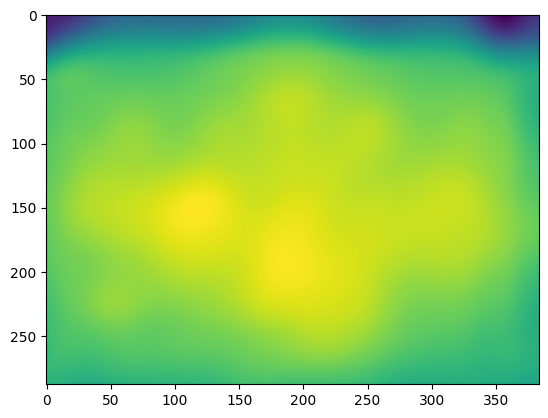

In [22]:
plt.imshow(sal_frames[-1].cpu())

In [23]:
sal_frames[-1]

tensor([[-24.5481, -24.5097, -24.4727,  ..., -23.3286, -23.2548, -23.1854],
        [-24.5537, -24.5097, -24.4671,  ..., -23.2808, -23.2088, -23.1412],
        [-24.5541, -24.5046, -24.4563,  ..., -23.2312, -23.1610, -23.0951],
        ...,
        [-15.2217, -15.2190, -15.2177,  ..., -16.1977, -16.2148, -16.2311],
        [-15.2349, -15.2346, -15.2356,  ..., -16.2481, -16.2651, -16.2813],
        [-15.2469, -15.2488, -15.2520,  ..., -16.2949, -16.3119, -16.3281]],
       device='cuda:0')